# Apply phenosensing to the RN

In [1]:
import os
import sys

from matplotlib import colors

os.environ["PROJ_LIB"] = "/home/abernard/miniconda3/envs/phenosensing/share/proj"
os.environ["PROJ_DATA"] = "/home/abernard/miniconda3/envs/phenosensing/share/proj"
os.environ["GDAL_DATA"] = "/home/abernard/miniconda3/envs/phenosensing/share/gdal"


import geopandas as gpd
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import rioxarray as rio
import pandas as pd
import phenosensing
from rasterio.enums import Resampling

from pyproj import CRS

print(CRS.from_epsg(2154))

EPSG:2154


In [2]:
gdf = gpd.read_file("../data/RNN_limite_poly_l93.shp")

gdf = gdf.set_crs("EPSG:2154")

gdf = gdf.to_crs("EPSG:4326")


gdf2 = gpd.read_file("../data/limite_RI_wgs84.shp")
gdf2 = gdf2.set_crs("EPSG:4326")

/home/abernard/miniconda3/envs/phenosensing/lib/python3.11/site-packages/pyogrio/raw.py:200: RuntimeWarning: organizePolygons() received an unexpected geometry.  Either a polygon with interior rings, or a polygon with less than 4 points, or a non-Polygon geometry.  Return arguments as a collection.
  return ogr_read(
/home/abernard/miniconda3/envs/phenosensing/lib/python3.11/site-packages/pyogrio/raw.py:200: RuntimeWarning: Geometry of polygon of fid 0 cannot be translated to Simple Geometry. All polygons will be contained in a multipolygon.
  return ogr_read(


## import the NETCDF HLS data

In [3]:
#### NET CDF ######

# HLS sentinel
ds_part1 = xr.open_dataset("../data/HLS_IMG/HLSS30.020_30m_2016.nc", decode_coords="all")
ds_part2 = xr.open_dataset("../data/HLS_IMG/HLSS30.020_30m_2017_2021.nc", decode_coords="all")
ds_part3 = xr.open_dataset("../data/HLS_IMG/HLSS30.020_30m_2022_2026.nc", decode_coords="all")

ds_s = xr.concat([ds_part1, ds_part2, ds_part3], dim="time")


# HLS landsat
ds_part1 = xr.open_dataset("../data/HLS_IMG/HLSL30.020_30m_2016.nc", decode_coords="all")
ds_part2 = xr.open_dataset("../data/HLS_IMG/HLSL30.020_30m_2017_2021.nc", decode_coords="all")
ds_part3 = xr.open_dataset("../data/HLS_IMG/HLSL30.020_30m_2022_2026.nc",decode_coords="all")

ds_l = xr.concat([ds_part1, ds_part2, ds_part3], dim="time", join="override")

In [4]:
ds_s2 = ds_s.rename({"B8A": "NIR"})
ds_l2 = ds_l.rename({"B05": "NIR"})

In [5]:
ds_s2 = ds_s2.assign_coords(sensor=("time", ["S30"] * ds_s2.sizes["time"]))
ds_l2 = ds_l2.assign_coords(sensor=("time", ["L30"] * ds_l2.sizes["time"]))

In [6]:
ds = xr.concat([ds_s2, ds_l2], dim="time", join="override").sortby("time")

In [7]:
# Dates où il y a plusieurs images
dates = pd.Index(ds.time.values)
dates_dupliquees = pd.unique(dates[dates.duplicated()])

# Masque des images à conserver
a_garder = ~(
    ds.time.isin(dates_dupliquees) &   # date dupliquée
    (ds.sensor == "L30")               # provenant de Landsat
)

ds = ds.sel(time=a_garder)

In [8]:
## compute the NDVI
red = ds["B04"]
nir = ds["NIR"]

ndvi = (nir - red) / (nir + red)
ds["NDVI"] = ndvi
ds["NDVI"].attrs = {
    "long_name": "Normalized Difference Vegetation Index"
}

In [9]:
fmask = ds["Fmask"].astype("uint8")
fmask = fmask.rio.write_crs("EPSG:4326")


# Décodage des bits Fmask
cloud = ((fmask >> 1) & 1) == 1
adjacent = ((fmask >> 2) & 1) == 1
shadow = ((fmask >> 3) & 1) == 1
snow = ((fmask >> 4) & 1) == 1


# Pixels conservés
good = (
    (~cloud)
    &
    (~adjacent)
    &
    (~shadow)
    &
    (~snow)
)

/home/abernard/miniconda3/envs/phenosensing/lib/python3.11/site-packages/xarray/core/duck_array_ops.py:268: RuntimeWarning: invalid value encountered in cast
  return data.astype(dtype, **kwargs)


In [10]:
ds_clean = ds.where(good)

In [11]:
# RN

clipped_ndvi = ds_clean["NDVI"].rio.clip(
    gdf.geometry,
    gdf.crs,
    drop=True
)


clipped_good = good.rio.clip(
    gdf.geometry,
    gdf.crs,
    drop=True
)

In [12]:
dates_valides = []
moyennes_ndvi = []
median_ndvi = []
ratios_good = []


for t in range(clipped_ndvi.sizes["time"]):

    ndvi_t = clipped_ndvi.isel(time=t)

    good_t = clipped_good.isel(time=t)


    # proportion de pixels valides
    ratio_good = good_t.mean().item()


    # garder seulement si >90% de pixels propres
    if ratio_good > 0.90:

        mean_ndvi = ndvi_t.where(good_t).mean().item()

        med_ndvi = ndvi_t.where(good_t).median().item()


        dates_valides.append(
            pd.to_datetime(str(ndvi_t.time.values))
        )

        moyennes_ndvi.append(mean_ndvi)
        median_ndvi.append(med_ndvi)

        ratios_good.append(ratio_good)

In [13]:
df = pd.DataFrame({
    "date": dates_valides,
    "mean_ndvi": moyennes_ndvi,
    "median_ndvi": median_ndvi,
    "ratio_good": ratios_good
})


df = df.sort_values("date")

In [14]:
df_clean = df[(df["mean_ndvi"] > 0.5) & (df["mean_ndvi"] < 0.9)]

In [15]:
import cftime

dates_valides_cftime = [  # nouveau xarr avec seulement les dates où -20% de pixels invalides
    cftime.DatetimeJulian(
        d.year,
        d.month,
        d.day
    )
    for d in dates_valides
]

ds_final = ds.sel(time=dates_valides_cftime)

In [16]:
ds_final["NDVI"] = ds_final["NDVI"].where(
    np.isfinite(ds_final["NDVI"]) &
    (ds_final["NDVI"] >= -1) &
    (ds_final["NDVI"] <= 1)
)

## Import the Deluzet maps of species distribution

In [17]:
# Charger la carte
massane1 = rio.open_rasterio(
    "../data/Cartes_Deluzet/5class_maps/Massane1_RF.tif",
    masked=True
)

massane2 = rio.open_rasterio(
    "../data/Cartes_Deluzet/5class_maps/Massane2_RF.tif",
    masked=True
)

In [18]:
# reproj en wgs84
massane1_wgs84 = massane1.rio.reproject("EPSG:4326")
massane2_wgs84 = massane2.rio.reproject("EPSG:4326")

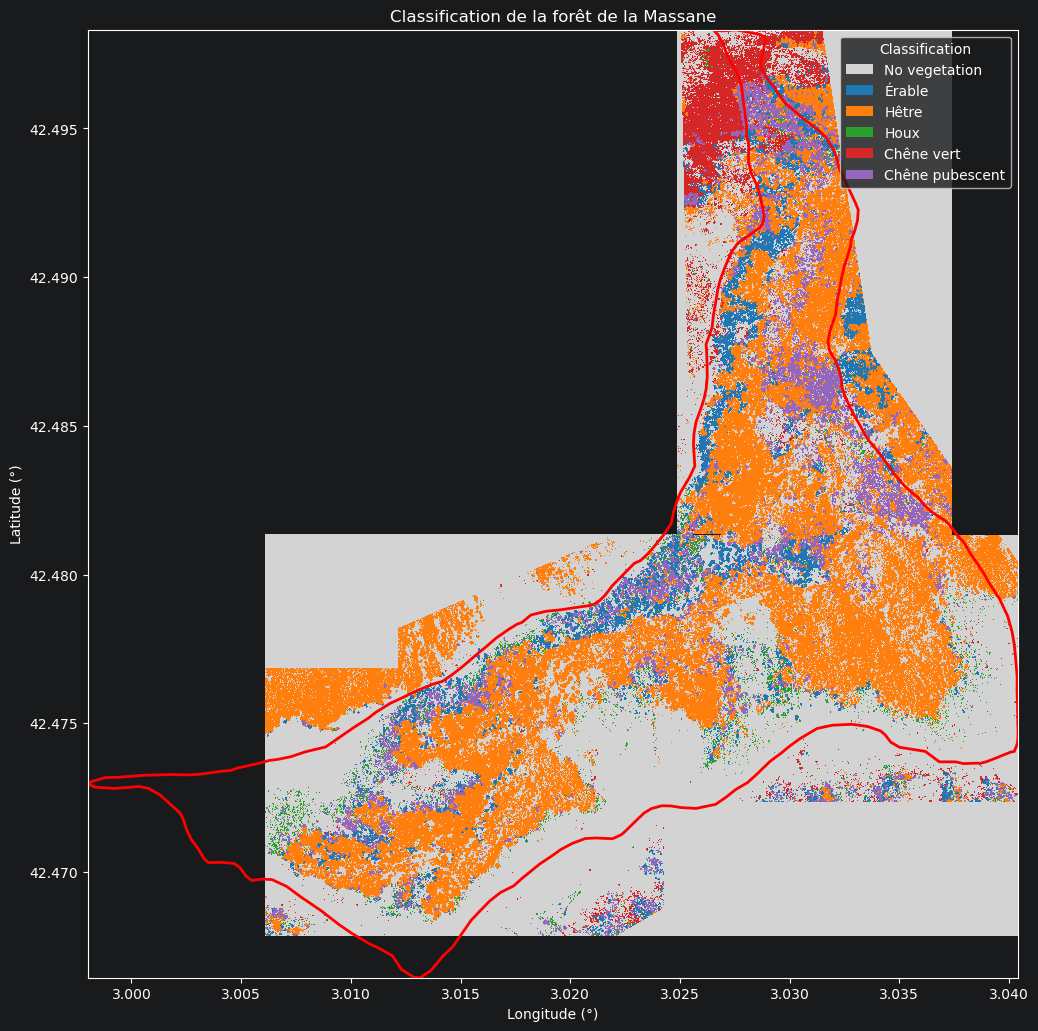

In [19]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

xmin, ymin, xmax, ymax = gdf.total_bounds

# 0 = non-végétation
# 1-5 = espèces
colors = [
    "lightgray",   # 0 - No vegetation
    "tab:blue",    # 1
    "tab:orange",  # 2
    "tab:green",   # 3
    "tab:red",     # 4
    "tab:purple"   # 5
]

cmap = ListedColormap(colors)

fig, ax = plt.subplots(figsize=(12, 15))

massane1_wgs84.squeeze().plot(
    ax=ax,
    cmap=cmap,
    vmin=0,
    vmax=5,
    add_colorbar=False
)

massane2_wgs84.squeeze().plot(
    ax=ax,
    cmap=cmap,
    vmin=0,
    vmax=5,
    add_colorbar=False
)

# Limite de la réserve
gdf.boundary.plot(
    ax=ax,
    color="red",
    linewidth=2
)

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

ax.set_xlabel("Longitude (°)")
ax.set_ylabel("Latitude (°)")

# Légende
legend_elements = [
    Patch(facecolor="lightgray", label="No vegetation"),
    Patch(facecolor="tab:blue", label="Érable"),
    Patch(facecolor="tab:orange", label="Hêtre"),
    Patch(facecolor="tab:green", label="Houx"),
    Patch(facecolor="tab:red", label="Chêne vert"),
    Patch(facecolor="tab:purple", label="Chêne pubescent"),
]

ax.legend(
    handles=legend_elements,
    title="Classification",
    loc="upper right"
)

ax.set_title("Classification de la forêt de la Massane")

plt.show()

In [20]:
# grille cible :
template = ds_final["NDVI"].isel(time=0, drop=True)

template = template.rio.set_spatial_dims(
    x_dim="xdim",
    y_dim="ydim"
)

template = template.rio.write_crs("EPSG:4326")

In [21]:
# merger les deux massage de deluzet
from rioxarray.merge import merge_arrays

massane_wgs84 = merge_arrays([massane1_wgs84, massane2_wgs84])

In [22]:
veg = xr.where(
    massane_wgs84.notnull(),
    (massane_wgs84 != 0).astype("float32"),
    np.nan
)

print("Valeurs du masque :", np.unique(veg.values))

Valeurs du masque : [ 0.  1. nan]


In [23]:
hetre = xr.where(
    massane_wgs84.notnull(),
    (massane_wgs84 == 2).astype("float32"),
    np.nan
)

print("Valeurs du masque :", np.unique(hetre.values))

Valeurs du masque : [ 0.  1. nan]


In [24]:
# verifier les proportions avant le resampling

total = veg.size
total_hetre = hetre.size

n_veg = np.sum(veg.values == 1)
n_noveg = np.sum(veg.values == 0)
n_nodata = np.sum(np.isnan(veg.values))
n_hetre = np.sum(hetre.values == 1)
n_nohetre = np.sum(hetre.values == 0)

print()
print("Haute résolution :")
print(f"Végétation     : {100*n_veg/total:.2f} %")
print(f"Non-végétation : {100*n_noveg/total:.2f} %")
print(f"NoData         : {100*n_nodata/total:.2f} %")

print(f"Hetre          : {100*n_hetre/total_hetre:.2f} %")
print(f"No Hetre       : {100*n_nohetre/total_hetre:.2f} %")


Haute résolution :
Végétation     : 21.54 %
Non-végétation : 37.66 %
NoData         : 40.80 %
Hetre          : 13.37 %
No Hetre       : 45.83 %


In [25]:
veg_fraction = veg.rio.reproject_match(
    template,
    resampling=Resampling.average
)

veg_fraction = veg_fraction.squeeze()

In [26]:
hetre_fraction = hetre.rio.reproject_match(
    template,
    resampling=Resampling.average
)

hetre_fraction = hetre_fraction.squeeze()

In [27]:
veg_mask = veg_fraction.where(
    veg_fraction > 0.60
)

In [28]:
hetre_mask = hetre_fraction.where(
    hetre_fraction > 0.6
)

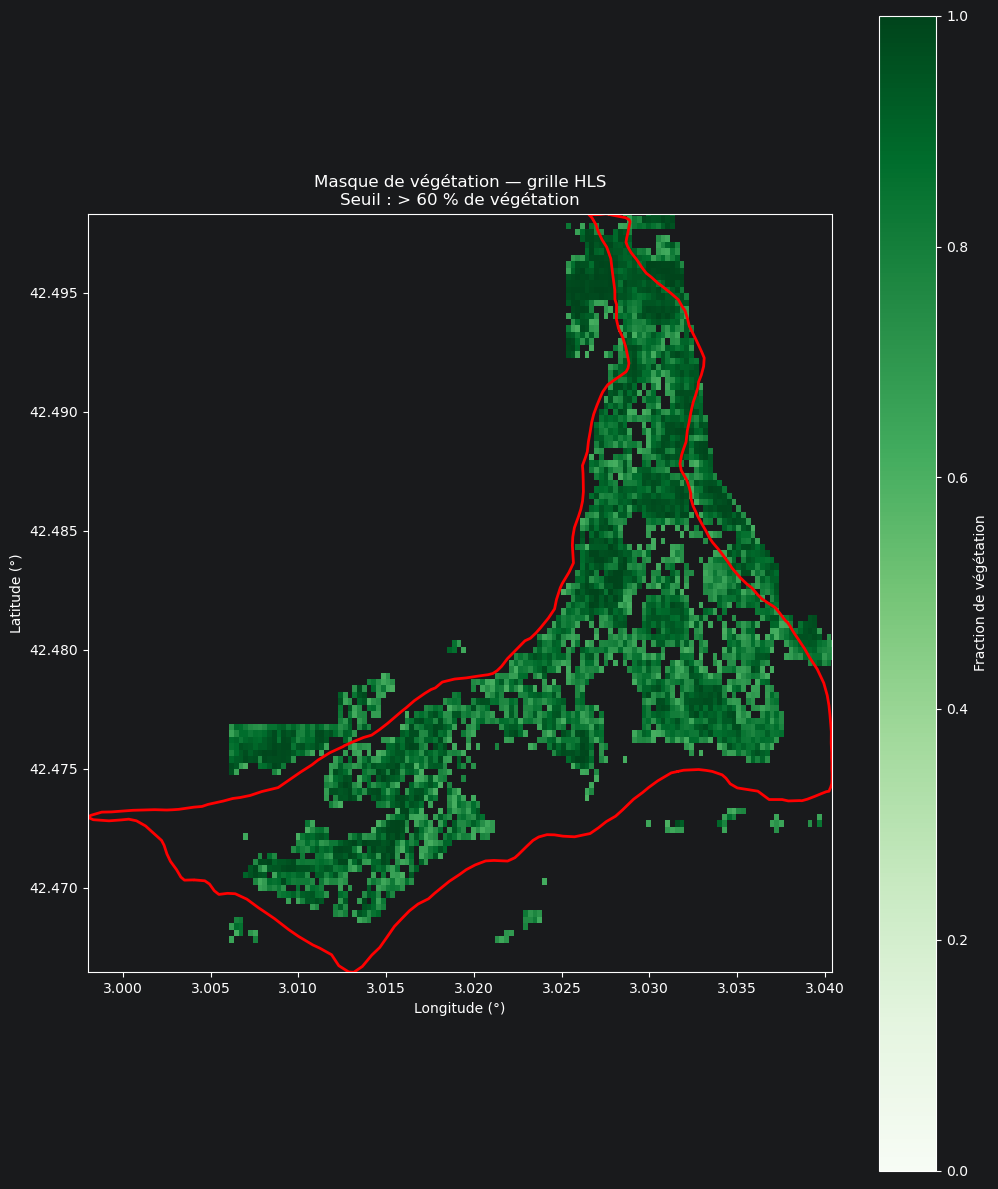

In [29]:
xmin, ymin, xmax, ymax = gdf.total_bounds

fig, ax = plt.subplots(figsize=(12, 15))

veg_mask.plot(
    ax=ax,
    cmap="Greens",
    vmin=0,
    vmax=1,
    add_colorbar=True,
    cbar_kwargs={
        "label": "Fraction de végétation"
    }
)

gdf.boundary.plot(
    ax=ax,
    color="red",
    linewidth=2
)

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

ax.set_xlabel("Longitude (°)")
ax.set_ylabel("Latitude (°)")
ax.set_title(
    "Masque de végétation — grille HLS\n"
    "Seuil : > 60 % de végétation"
)

plt.show()

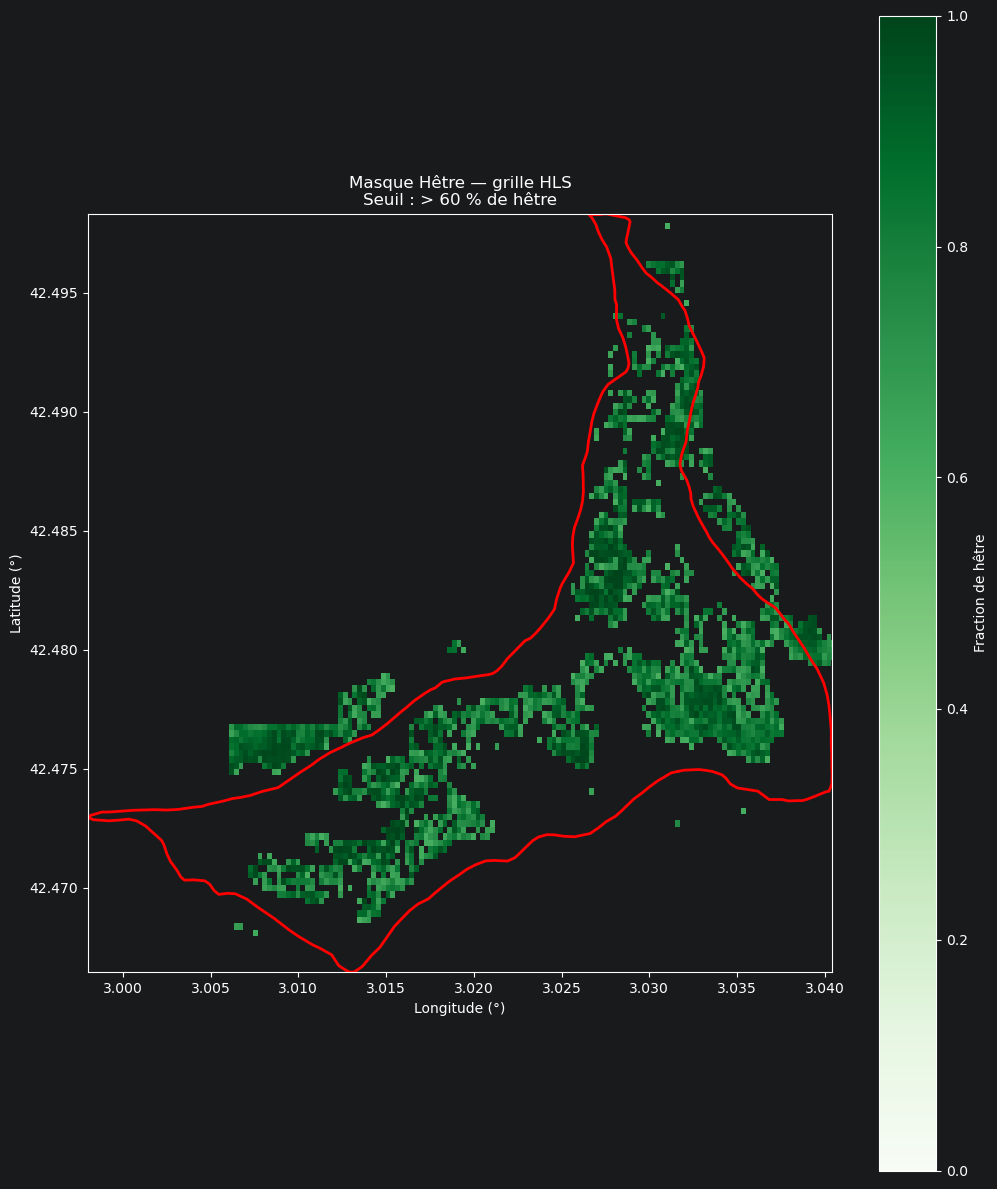

In [30]:
xmin, ymin, xmax, ymax = gdf.total_bounds

fig, ax = plt.subplots(figsize=(12, 15))

hetre_mask.plot(
    ax=ax,
    cmap="Greens",
    vmin=0,
    vmax=1,
    add_colorbar=True,
    cbar_kwargs={
        "label": "Fraction de hêtre"
    }
)

gdf.boundary.plot(
    ax=ax,
    color="red",
    linewidth=2
)

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

ax.set_xlabel("Longitude (°)")
ax.set_ylabel("Latitude (°)")
ax.set_title(
    "Masque Hêtre — grille HLS\n"
    "Seuil : > 60 % de hêtre"
)

plt.show()

In [31]:
# rename les dimensions (très important pour la suite)
veg_mask = veg_mask.rename({
    "y": "ydim",
    "x": "xdim"
})

hetre_mask = hetre_mask.rename({
    "y": "ydim",
    "x": "xdim"
})

# Phenosensing sur les images (que 2025 pour l'instant)

In [32]:
# ============================================================
# 2. Sélection de l'année 2025
# ============================================================

HLS_2025 = ds_final.sel(
    time=ds_final.time.dt.year == 2018
)

HLS_2025 = HLS_2025.where(
    hetre_mask.notnull()
)

print("\nStack 2025 :")
print(HLS_2025)

print("\nNombre d'images :", HLS_2025.sizes["time"])


Stack 2025 :
<xarray.Dataset> Size: 43MB
Dimensions:      (time: 26, ydim: 167, xdim: 205)
Coordinates:
  * time         (time) object 208B 2018-01-18 00:00:00 ... 2018-12-29 00:00:00
    sensor       (time) <U3 312B 'S30' 'S30' 'L30' 'S30' ... 'S30' 'S30' 'S30'
  * ydim         (ydim) float64 1kB 42.51 42.51 42.51 ... 42.46 42.46 42.46
  * xdim         (xdim) float64 2kB 3.001 3.001 3.002 ... 3.056 3.056 3.056
    crs          int8 1B -127
    band         int64 8B 1
    spatial_ref  int64 8B 0
Data variables:
    B02          (time, ydim, xdim) float64 7MB nan nan nan nan ... nan nan nan
    B03          (time, ydim, xdim) float64 7MB nan nan nan nan ... nan nan nan
    B04          (time, ydim, xdim) float64 7MB nan nan nan nan ... nan nan nan
    NIR          (time, ydim, xdim) float64 7MB nan nan nan nan ... nan nan nan
    Fmask        (time, ydim, xdim) float64 7MB nan nan nan nan ... nan nan nan
    NDVI         (time, ydim, xdim) float64 7MB nan nan nan nan ... nan nan nan
At

In [33]:
NDVI_2025 = HLS_2025["NDVI"]
print(NDVI_2025)

<xarray.DataArray 'NDVI' (time: 26, ydim: 167, xdim: 205)> Size: 7MB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
...
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, 

In [34]:
# ajouter le DOY

NDVI_2025 = NDVI_2025.assign_coords(
    doy=(
        "time",
        NDVI_2025.time.dt.dayofyear.data
    )
)

In [62]:
shape_2025 = NDVI_2025.pheno.PhenoShape(
    interpolType="whittaker",
    rollWindow=3,
    #nGS= 15
    nGS=HLS_2025.sizes["time"] # or change manually
)

print(shape_2025)

<xarray.DataArray 'NDVI' (doy: 26, ydim: 167, xdim: 205)> Size: 7MB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
...
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, n

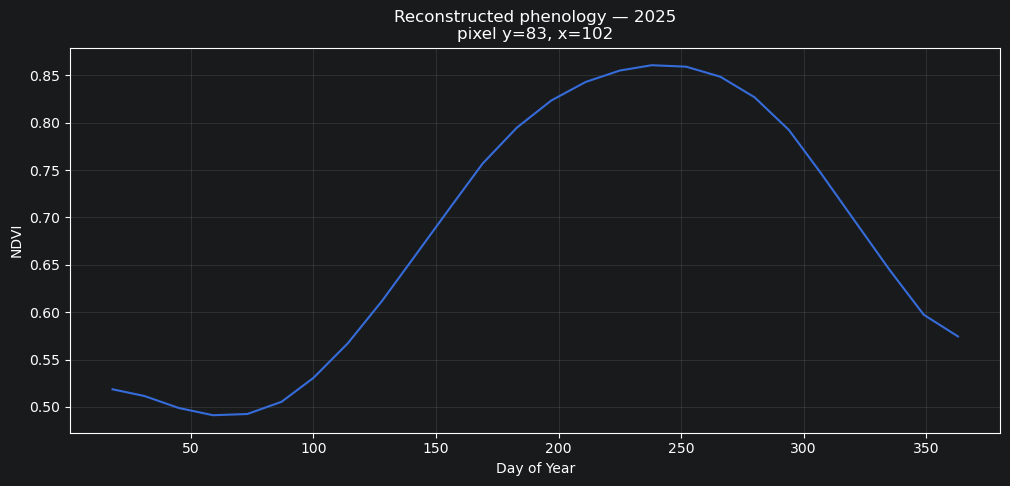

In [63]:
# ============================================================
# 5. Tester la courbe d'un pixel
# ============================================================

y0 = NDVI_2025.sizes["ydim"] // 2 # recup du pixel central
x0 = NDVI_2025.sizes["xdim"] // 2

pixel_curve = shape_2025.isel(
    ydim=y0,
    xdim=x0
)

plt.figure(figsize=(12, 5))

plt.plot(
    pixel_curve.doy,
    pixel_curve
)

plt.xlabel("Day of Year")
plt.ylabel("NDVI")

plt.title(
    f"Reconstructed phenology — 2025\n"
    f"pixel y={y0}, x={x0}"
)

plt.grid(alpha=0.2)

plt.show()

Pixels : 34235
Points par courbe : 26


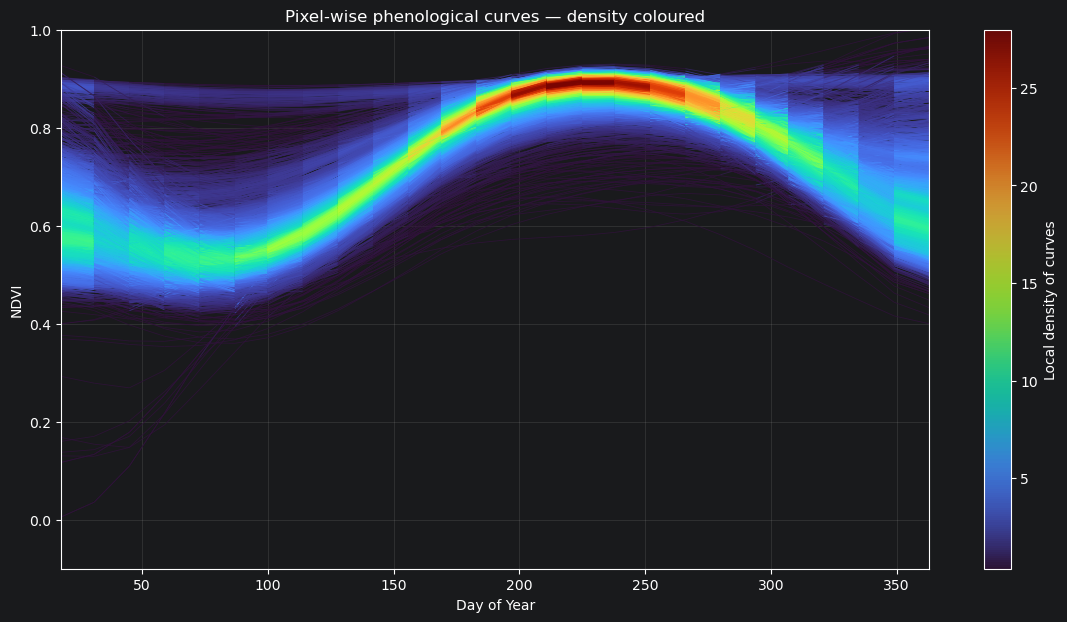

In [64]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize
from scipy.ndimage import gaussian_filter

# region bigplot




curves = shape_2025.values

# (doy, ydim, xdim) -> (doy, pixels)
curves = curves.reshape(
    curves.shape[0],
    -1
)

doy = shape_2025.doy.values

print("Pixels :", curves.shape[1])
print("Points par courbe :", curves.shape[0])



# Grille de densité


nx_density = 300
ny_density = 300

xedges = np.linspace(
    doy.min(),
    doy.max(),
    nx_density + 1
)

yedges = np.linspace(
    -0.1,
    1.0,
    ny_density + 1
)



# Histogramme 2D


X = np.broadcast_to(
    doy[:, None],
    curves.shape
)

Y = curves

valid = np.isfinite(Y)

density, _, _ = np.histogram2d(
    X[valid],
    Y[valid],
    bins=[xedges, yedges]
)



# Lisser la densité


density = gaussian_filter(
    density,
    sigma=2
)



#Associer une densité à chaque point


ix = np.searchsorted(xedges, X) - 1
iy = np.searchsorted(yedges, Y) - 1

ix = np.clip(
    ix,
    0,
    nx_density - 1
)

iy = np.clip(
    iy,
    0,
    ny_density - 1
)

point_density = np.zeros_like(Y)

point_density[valid] = density[
    ix[valid],
    iy[valid]
]



# Construire les segments


x0 = X[:-1]
x1 = X[1:]

y0 = Y[:-1]
y1 = Y[1:]

d0 = point_density[:-1]
d1 = point_density[1:]

valid_segments = (
    np.isfinite(y0) &
    np.isfinite(y1)
)

segments = np.stack(
    [
        np.stack(
            [x0[valid_segments], y0[valid_segments]],
            axis=1
        ),
        np.stack(
            [x1[valid_segments], y1[valid_segments]],
            axis=1
        )
    ],
    axis=1
)

segment_density = (
    d0[valid_segments] +
    d1[valid_segments]
) / 2



# Limiter l'effet des zones extrêmement denses


vmin = np.percentile(
    segment_density,
    1
)

vmax = np.percentile(
    segment_density,
    99
)

norm = Normalize(
    vmin=vmin,
    vmax=vmax
)



#Plot


fig, ax = plt.subplots(
    figsize=(14, 7)
)

lc = LineCollection(
    segments,
    cmap="turbo",
    norm=norm,
    linewidths=0.6,
    alpha=0.8
)

lc.set_array(
    segment_density
)

ax.add_collection(lc)

ax.set_xlim(
    doy.min(),
    doy.max()
)

ax.set_ylim(
    -0.1,
    1.0
)

ax.set_xlabel("Day of Year")
ax.set_ylabel("NDVI")

ax.set_title(
    "Pixel-wise phenological curves — density coloured"
)

ax.grid(alpha=0.2)

cbar = fig.colorbar(
    lc,
    ax=ax
)

cbar.set_label(
    "Local density of curves"
)

# endregion

plt.show()

# metriques pheno

In [38]:
# ============================================================
# 7. Extraction des métriques avec DER
# ============================================================

lsp_2025 = shape_2025.pheno.PhenoLSP(
    extraction="der",
    hemisphere="north"
)

print("\nMétriques phénologiques :")
print(lsp_2025)

/home/abernard/miniconda3/envs/phenosensing/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/abernard/miniconda3/envs/phenosensing/lib/python3.11/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/abernard/PhenoSensing/phenosensing/utils.py:293: RuntimeWarning: invalid value encountered in divide
  ros = (phen[ieos] - vpos) / (eos - pos)
/home/abernard/PhenoSensing/phenosensing/utils.py:290: RuntimeWarning: invalid value encountered in divide
  rog = (vpos - phen[isos]) / (pos - sos)



Métriques phénologiques :
<xarray.Dataset> Size: 5MB
Dimensions:      (ydim: 167, xdim: 205)
Coordinates:
  * ydim         (ydim) float64 1kB 42.51 42.51 42.51 ... 42.46 42.46 42.46
  * xdim         (xdim) float64 2kB 3.001 3.001 3.002 ... 3.056 3.056 3.056
    crs          int8 1B -127
    band         int64 8B 1
    spatial_ref  int64 8B 0
Data variables: (12/18)
    sos          (ydim, xdim) float64 274kB nan nan nan nan ... nan nan nan nan
    pos          (ydim, xdim) float64 274kB nan nan nan nan ... nan nan nan nan
    eos          (ydim, xdim) float64 274kB nan nan nan nan ... nan nan nan nan
    vsos         (ydim, xdim) float64 274kB nan nan nan nan ... nan nan nan nan
    vpos         (ydim, xdim) float64 274kB nan nan nan nan ... nan nan nan nan
    veos         (ydim, xdim) float64 274kB nan nan nan nan ... nan nan nan nan
    ...           ...
    ios          (ydim, xdim) float64 274kB nan nan nan nan ... nan nan nan nan
    rog          (ydim, xdim) float64 274kB nan n

vmin : 128.0
vmax : 156.0


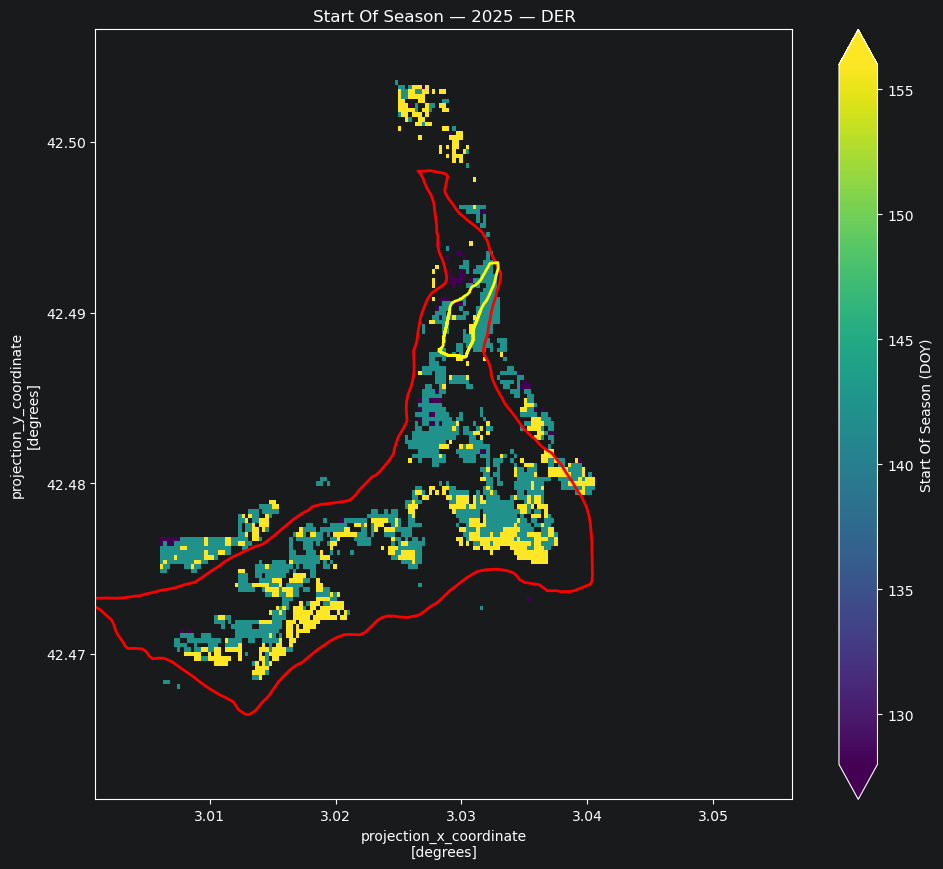

In [39]:
sos = lsp_2025["sos"]

# Découper SOS selon le polygone gdf2
sos_gdf = sos.rio.clip(
    gdf.geometry,
    gdf.crs,
    drop=True
)

# Calcul des percentiles uniquement dans gdf2
vmin = float(sos_gdf.quantile(0.02))
vmax = float(sos_gdf.quantile(0.98))

print("vmin :", vmin)
print("vmax :", vmax)

fig, ax = plt.subplots(
    1, 1,
    figsize=(12, 10)
)

sos.plot(
    ax=ax,
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    cbar_kwargs={
        "label": "Start Of Season (DOY)"
    }
)

gdf.boundary.plot(
    ax=ax,
    color="red",
    linewidth=2
)

gdf2.boundary.plot(
    ax=ax,
    color="yellow",
    linewidth=2
)

plt.title("Start Of Season — 2025 — DER")

plt.show()

vmin : 225.0
vmax : 363.0


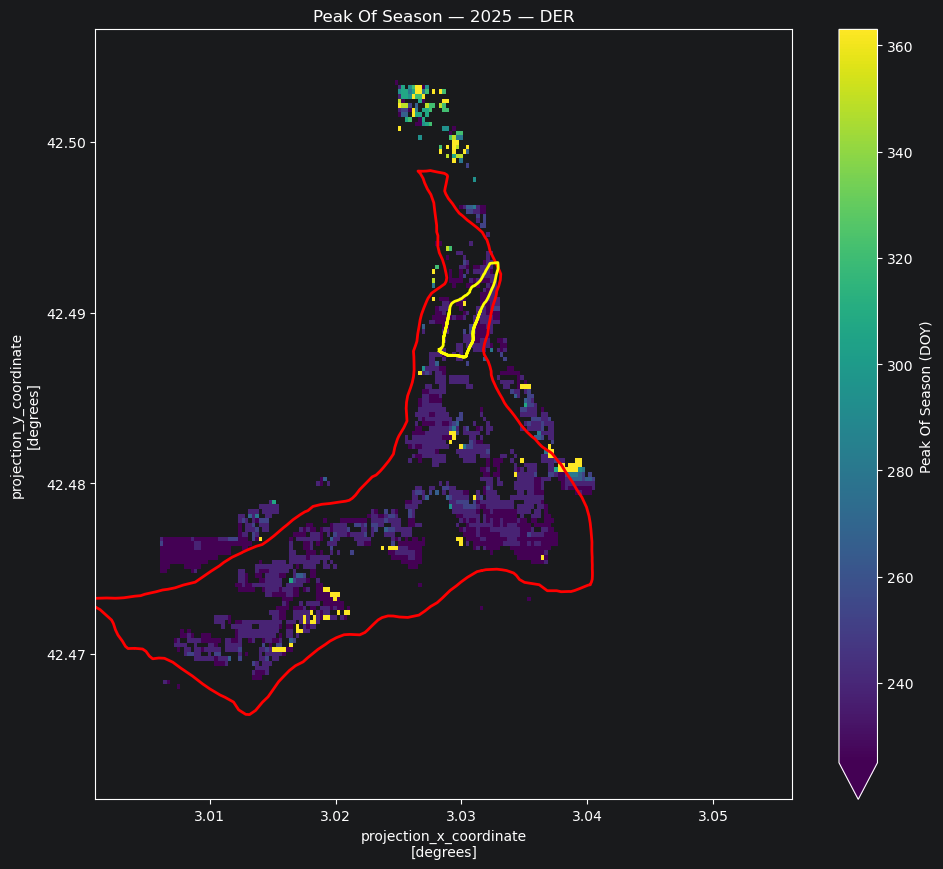

In [40]:
pos = lsp_2025["pos"]

# Découper POS selon le polygone gdf
pos_gdf = pos.rio.clip(
    gdf.geometry,
    gdf.crs,
    drop=True
)

# Calcul des percentiles uniquement dans gdf
vmin = float(pos_gdf.quantile(0.02))
vmax = float(pos_gdf.quantile(0.98))

print("vmin :", vmin)
print("vmax :", vmax)

fig, ax = plt.subplots(
    1, 1,
    figsize=(12, 10)
)

pos.plot(
    ax=ax,
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    cbar_kwargs={
        "label": "Peak Of Season (DOY)"
    }
)

gdf.boundary.plot(
    ax=ax,
    color="red",
    linewidth=2
)

gdf2.boundary.plot(
    ax=ax,
    color="yellow",
    linewidth=2
)

plt.title("Peak Of Season — 2025 — DER")

plt.show()

vmin : 266.0
vmax : 363.0


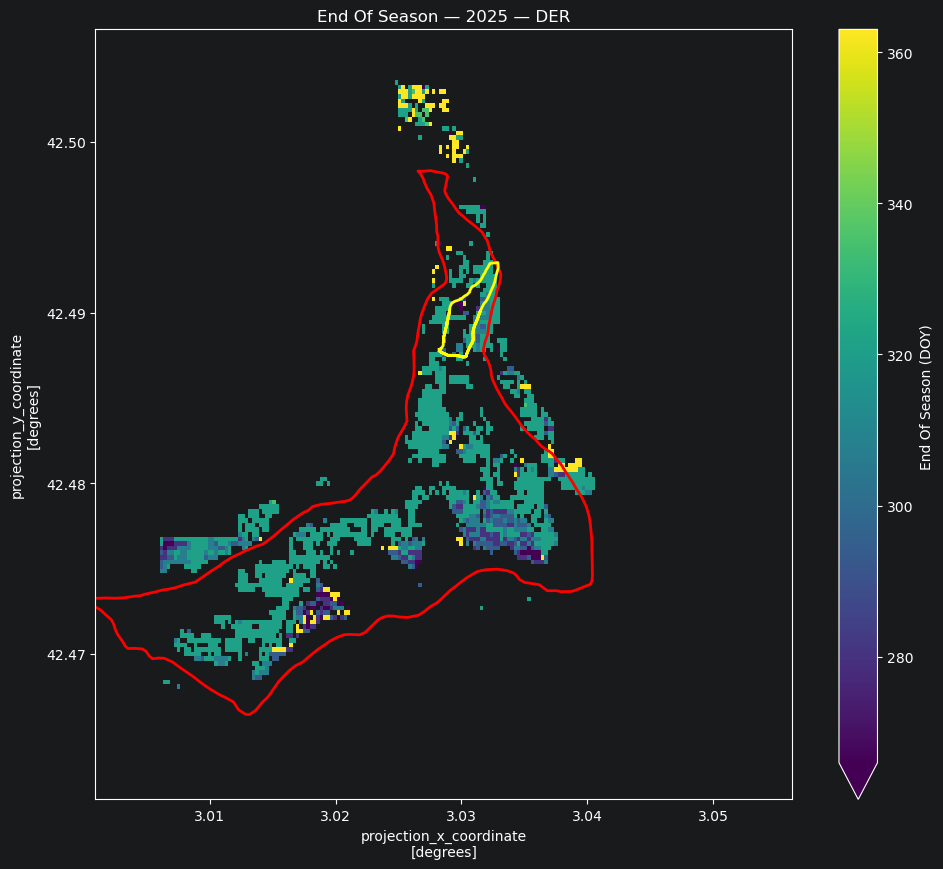

In [41]:
eos = lsp_2025["eos"]

# Découper EOS selon le polygone gdf
eos_gdf = eos.rio.clip(
    gdf.geometry,
    gdf.crs,
    drop=True
)

# Calcul des percentiles uniquement dans gdf
vmin = float(eos_gdf.quantile(0.02))
vmax = float(eos_gdf.quantile(0.98))

print("vmin :", vmin)
print("vmax :", vmax)

fig, ax = plt.subplots(
    1, 1,
    figsize=(12, 10)
)

eos.plot(
    ax=ax,
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    cbar_kwargs={
        "label": "End Of Season (DOY)"
    }
)

gdf.boundary.plot(
    ax=ax,
    color="red",
    linewidth=2
)

gdf2.boundary.plot(
    ax=ax,
    color="yellow",
    linewidth=2
)

plt.title("End Of Season — 2025 — DER")

plt.show()

# Calcul des phenos (toutes les années)

In [42]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr

years = [2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]

results = {}

for year in years:

    print(f"\n{'='*50}")
    print(f"ANNÉE {year}")
    print(f"{'='*50}")

    # --------------------------------------------------------
    # Sélection de l'année
    # --------------------------------------------------------

    HLS_year = ds_final.sel(
        time=ds_final.time.dt.year == year
    )

    # --------------------------------------------------------
    # Clip à la zone d'étude
    # --------------------------------------------------------

    HLS_year = HLS_year.rio.set_spatial_dims(
        x_dim="xdim",
        y_dim="ydim"
    )

    HLS_year = HLS_year.rio.write_crs("EPSG:4326")

    HLS_year = HLS_year.rio.clip(
        gdf.geometry,
        gdf.crs,
        drop=True
    )

    # --------------------------------------------------------
    # Masque hêtre
    # --------------------------------------------------------

    HLS_year = HLS_year.where(
        hetre_mask.notnull()
    )

    print("Nombre d'images :", HLS_year.sizes["time"])

    # --------------------------------------------------------
    # NDVI
    # --------------------------------------------------------

    NDVI_year = HLS_year["NDVI"]

    # DOY
    NDVI_year = NDVI_year.assign_coords(
        doy=(
            "time",
            NDVI_year.time.dt.dayofyear.data
        )
    )

    # --------------------------------------------------------
    # Reconstruction phénologique
    # --------------------------------------------------------

    shape_year = NDVI_year.pheno.PhenoShape(
        interpolType="whittaker",
        rollWindow=4,
        nGS=HLS_year.sizes["time"]
    )

    # --------------------------------------------------------
    # Métriques phénologiques
    # --------------------------------------------------------

    lsp_year = shape_year.pheno.PhenoLSP(
        extraction="der",
        hemisphere="north"
    )

    # --------------------------------------------------------
    # Stockage
    # --------------------------------------------------------

    results[year] = {
        "HLS": HLS_year,
        "NDVI": NDVI_year,
        "shape": shape_year,
        "lsp": lsp_year
    }

    print("Calcul terminé.")


ANNÉE 2016
Nombre d'images : 17


/home/abernard/miniconda3/envs/phenosensing/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/abernard/miniconda3/envs/phenosensing/lib/python3.11/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/abernard/PhenoSensing/phenosensing/utils.py:293: RuntimeWarning: invalid value encountered in divide
  ros = (phen[ieos] - vpos) / (eos - pos)


Calcul terminé.

ANNÉE 2017
Nombre d'images : 35


/home/abernard/miniconda3/envs/phenosensing/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/abernard/miniconda3/envs/phenosensing/lib/python3.11/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/abernard/PhenoSensing/phenosensing/utils.py:290: RuntimeWarning: invalid value encountered in divide
  rog = (vpos - phen[isos]) / (pos - sos)
/home/abernard/PhenoSensing/phenosensing/utils.py:293: RuntimeWarning: invalid value encountered in divide
  ros = (phen[ieos] - vpos) / (eos - pos)


Calcul terminé.

ANNÉE 2018
Nombre d'images : 26


...

Calcul terminé.

ANNÉE 2024
Nombre d'images : 48


/home/abernard/miniconda3/envs/phenosensing/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/abernard/miniconda3/envs/phenosensing/lib/python3.11/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/abernard/PhenoSensing/phenosensing/utils.py:293: RuntimeWarning: invalid value encountered in divide
  ros = (phen[ieos] - vpos) / (eos - pos)


Calcul terminé.

ANNÉE 2025
Nombre d'images : 50


/home/abernard/miniconda3/envs/phenosensing/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/abernard/miniconda3/envs/phenosensing/lib/python3.11/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/abernard/PhenoSensing/phenosensing/utils.py:293: RuntimeWarning: invalid value encountered in divide
  ros = (phen[ieos] - vpos) / (eos - pos)


Calcul terminé.


# phenos individuelles

In [43]:
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize
from scipy.ndimage import gaussian_filter


def plot_phenology_curves(ax, shape):

    curves = shape.values

    # (doy, ydim, xdim) -> (doy, pixels)
    curves = curves.reshape(
        curves.shape[0],
        -1
    )

    doy = shape.doy.values

    X = np.broadcast_to(
        doy[:, None],
        curves.shape
    )

    Y = curves

    valid = np.isfinite(Y)

    # --------------------------------------------------------
    # Densité
    # --------------------------------------------------------

    nx_density = 300
    ny_density = 300

    xedges = np.linspace(
        doy.min(),
        doy.max(),
        nx_density + 1
    )

    yedges = np.linspace(
        -0.1,
        1.0,
        ny_density + 1
    )

    density, _, _ = np.histogram2d(
        X[valid],
        Y[valid],
        bins=[xedges, yedges]
    )

    density = gaussian_filter(
        density,
        sigma=2
    )

    # --------------------------------------------------------
    # Densité associée aux points
    # --------------------------------------------------------

    ix = np.searchsorted(xedges, X) - 1
    iy = np.searchsorted(yedges, Y) - 1

    ix = np.clip(
        ix,
        0,
        nx_density - 1
    )

    iy = np.clip(
        iy,
        0,
        ny_density - 1
    )

    point_density = np.zeros_like(Y)

    point_density[valid] = density[
        ix[valid],
        iy[valid]
    ]

    # --------------------------------------------------------
    # Segments
    # --------------------------------------------------------

    x0 = X[:-1]
    x1 = X[1:]

    y0 = Y[:-1]
    y1 = Y[1:]

    d0 = point_density[:-1]
    d1 = point_density[1:]

    valid_segments = (
        np.isfinite(y0) &
        np.isfinite(y1)
    )

    segments = np.stack(
        [
            np.stack(
                [
                    x0[valid_segments],
                    y0[valid_segments]
                ],
                axis=1
            ),
            np.stack(
                [
                    x1[valid_segments],
                    y1[valid_segments]
                ],
                axis=1
            )
        ],
        axis=1
    )

    segment_density = (
        d0[valid_segments] +
        d1[valid_segments]
    ) / 2

    # --------------------------------------------------------
    # Normalisation
    # --------------------------------------------------------

    vmin = np.percentile(
        segment_density,
        1
    )

    vmax = np.percentile(
        segment_density,
        99
    )

    norm = Normalize(
        vmin=vmin,
        vmax=vmax
    )

    # --------------------------------------------------------
    # Plot
    # --------------------------------------------------------

    lc = LineCollection(
        segments,
        cmap="turbo",
        norm=norm,
        linewidths=0.6,
        alpha=0.8
    )

    lc.set_array(segment_density)

    ax.add_collection(lc)

    ax.set_xlim(
        doy.min(),
        doy.max()
    )

    ax.set_ylim(
        -0.1,
        1.0
    )

    ax.set_xlabel("Day of Year")
    ax.set_ylabel("NDVI")

    ax.grid(alpha=0.2)

    return lc


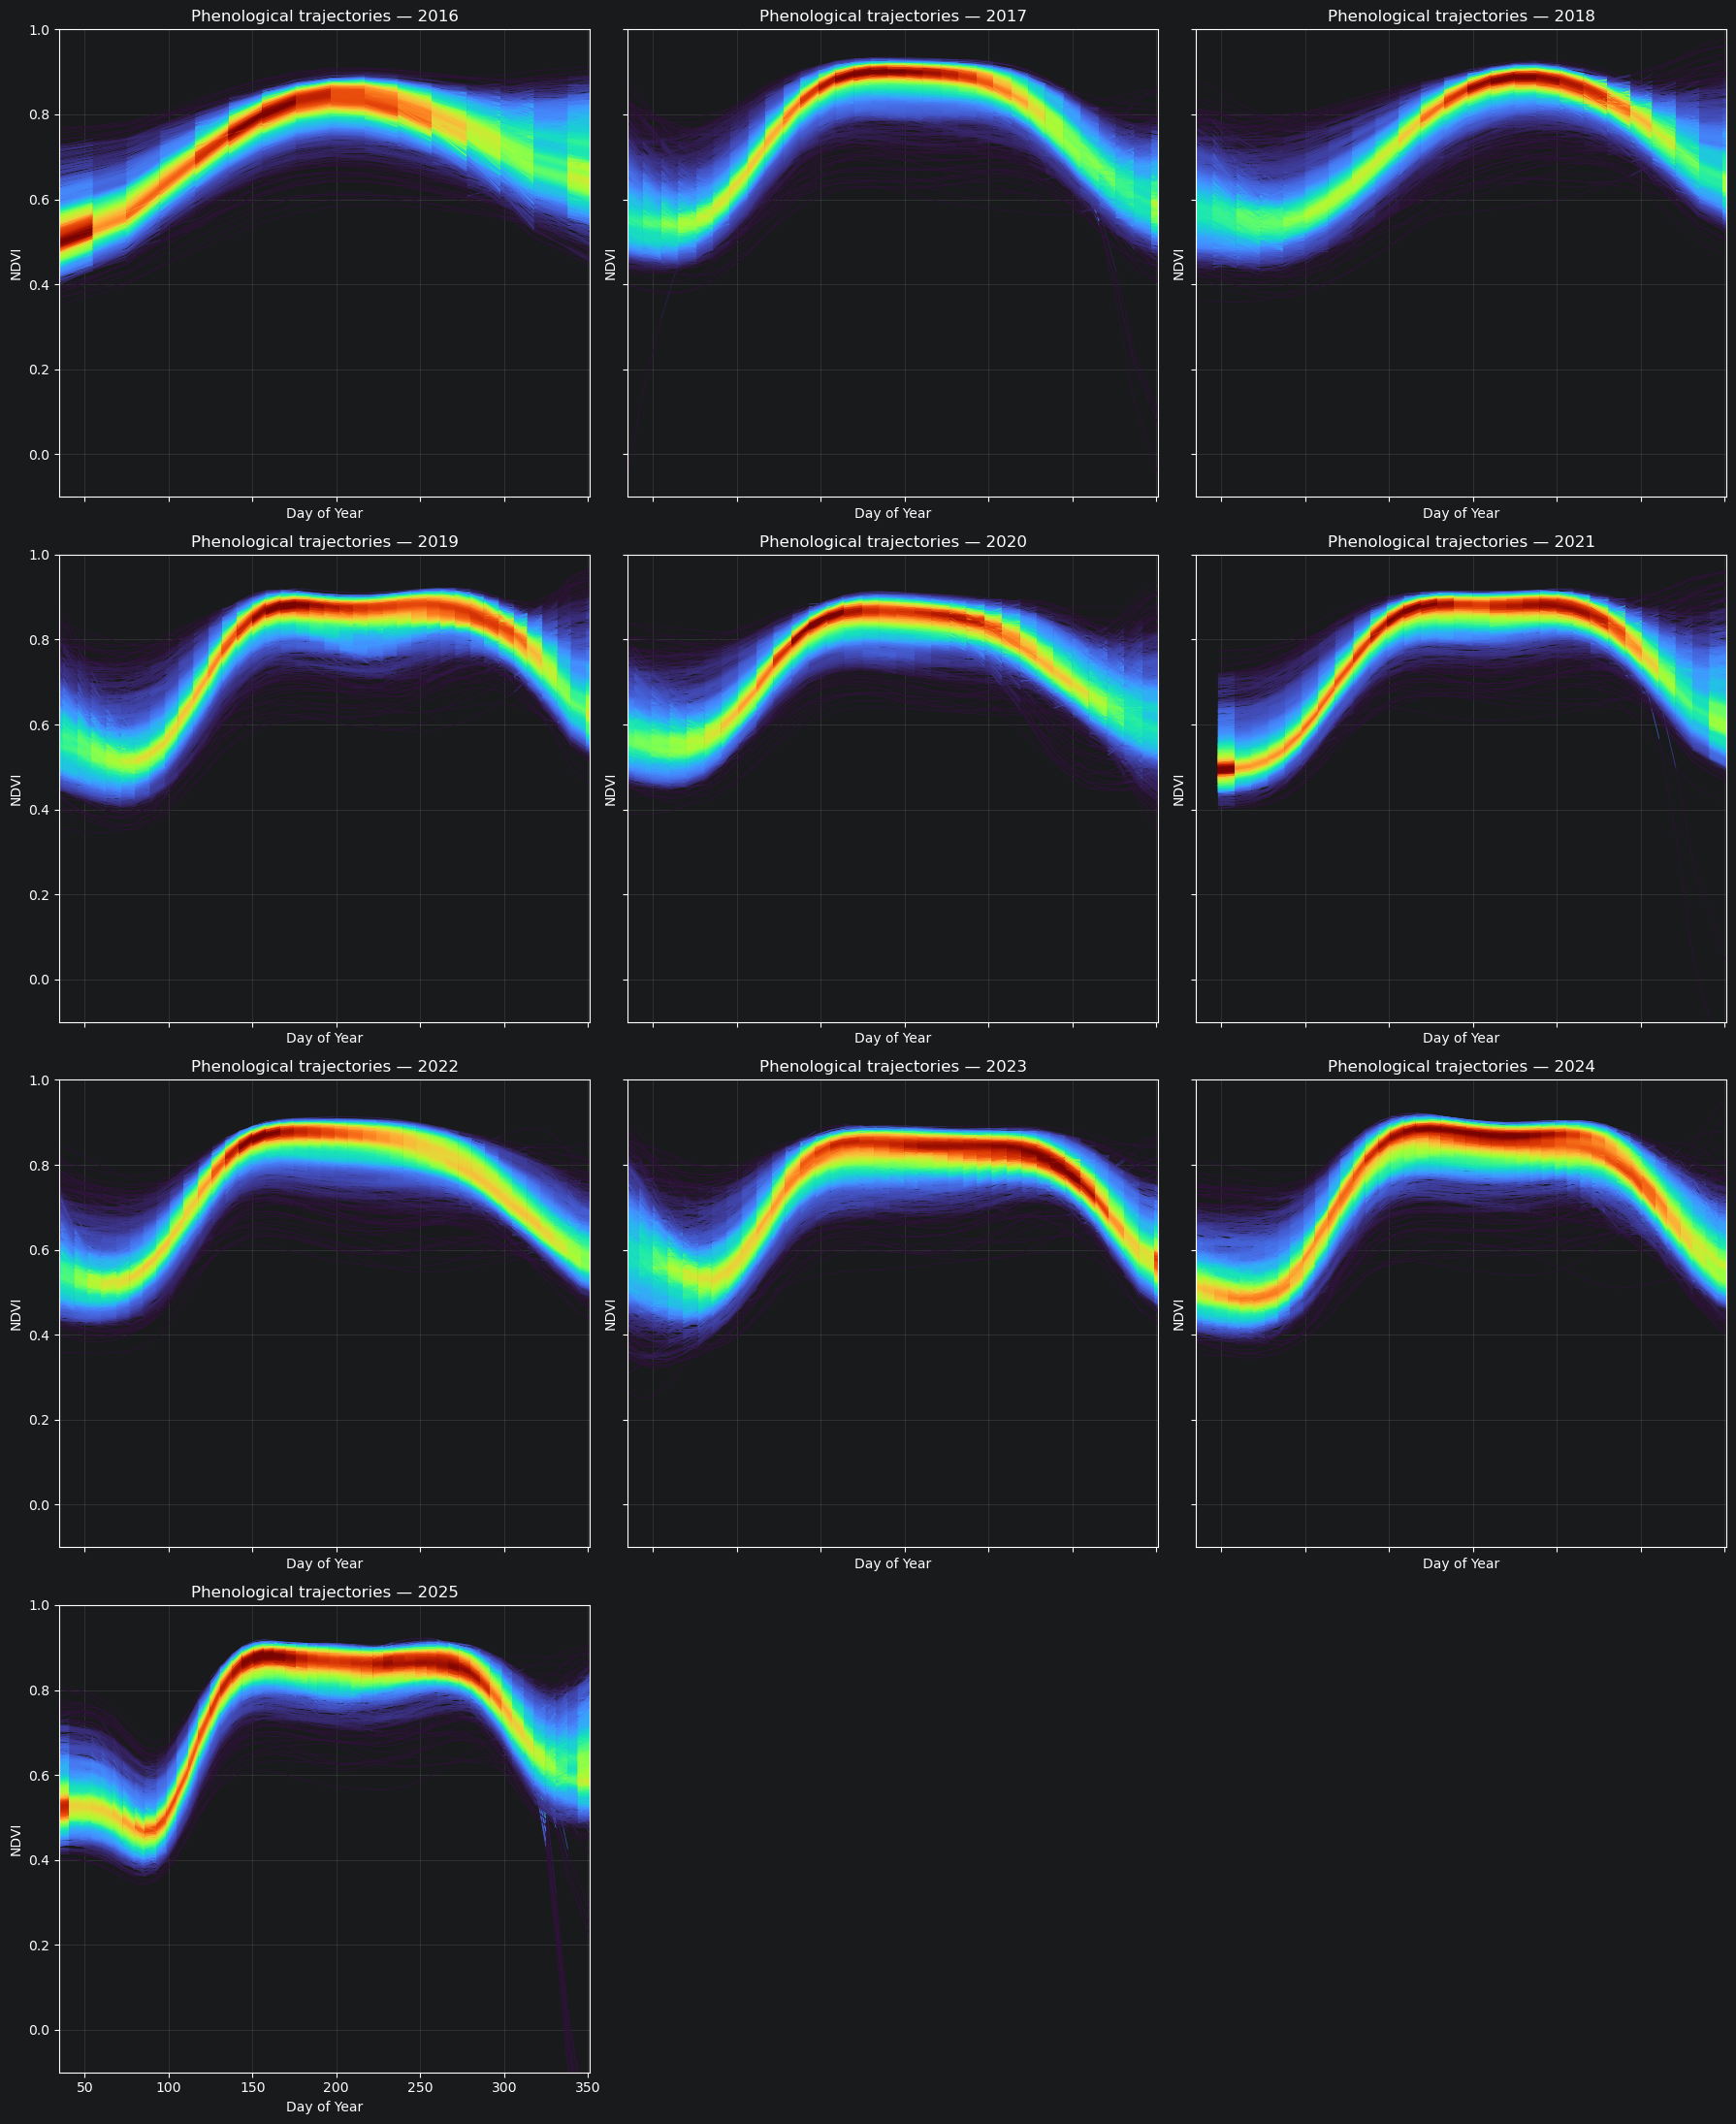

In [44]:
fig, axes = plt.subplots(
    4,
    3,
    figsize=( 18, 22),
    sharex=True,
    sharey=True
)

axes = axes.flatten()

for ax, year in zip(axes, years):

    shape = results[year]["shape"]

    plot_phenology_curves(
        ax,
        shape
    )

    ax.set_title(
        f"Phenological trajectories — {year}"
    )

# Cacher les cases inutilisées
for ax in axes[len(years):]:
    ax.set_visible(False)

plt.tight_layout()

plt.show()

# comparaisons interannuelles HLS (moyenne sur la carte de Deluzet)

In [45]:
# reduire des dims pour avoir un NDVI moyen par date dans le masque :

phenology_curves_mean = {}
mean_ndvi_years = {}

for year in years:

    print(f"\n================ {year} ================")

    # --------------------------------------------------------
    # Série NDVI des pixels de hêtre
    # --------------------------------------------------------

    NDVI_year = results[year]["NDVI"]

    # Moyenne spatiale sur les pixels de hêtre
    NDVI_mean = NDVI_year.mean(
        dim=("ydim", "xdim"),
        skipna=True
    )

    print(
        f"Nombre d'observations : {NDVI_mean.time.size}"
    )

    # --------------------------------------------------------
    # Ajouter le DOY
    # --------------------------------------------------------

    NDVI_mean = NDVI_mean.assign_coords(
        doy=(
            "time",
            NDVI_mean.time.dt.dayofyear.data
        )
    )

    # --------------------------------------------------------
    # Reconstruction phénologique
    # --------------------------------------------------------

    shape = NDVI_mean.pheno.PhenoShape(
        interpolType="whittaker",
        rollWindow=5,
        nGS=52
    )

    # Stockage
    mean_ndvi_years[year] = NDVI_mean
    phenology_curves_mean[year] = shape

    print("Calcul terminé.")


================ 2016 ================
Nombre d'observations : 17
Calcul terminé.

================ 2017 ================
Nombre d'observations : 35
Calcul terminé.

================ 2018 ================
Nombre d'observations : 26
Calcul terminé.

================ 2019 ================
Nombre d'observations : 42
Calcul terminé.

================ 2020 ================
Nombre d'observations : 35
Calcul terminé.

================ 2021 ================
Nombre d'observations : 31
Calcul terminé.

================ 2022 ================
Nombre d'observations : 44
Calcul terminé.

================ 2023 ================
Nombre d'observations : 41
Calcul terminé.

================ 2024 ================
Nombre d'observations : 48
Calcul terminé.

================ 2025 ================
Nombre d'observations : 50
Calcul terminé.


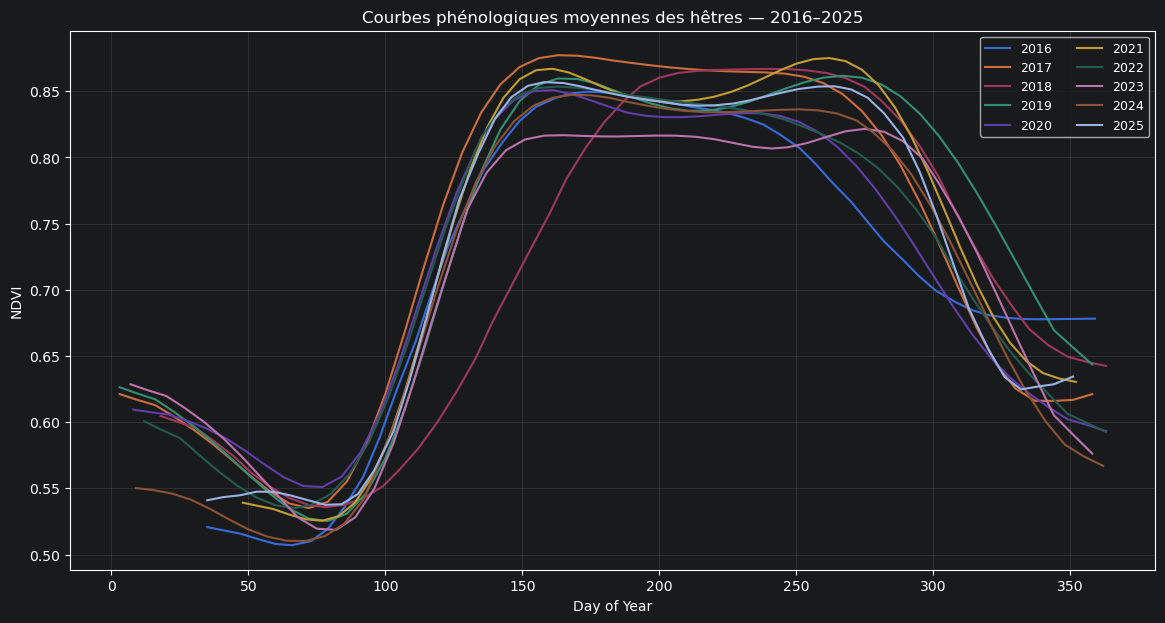

In [46]:
plt.figure(figsize=(14, 7))

for year, curve in phenology_curves_mean.items():

    plt.plot(
        curve.doy,
        curve,
        label=str(year)
    )

plt.xlabel("Day of Year")
plt.ylabel("NDVI")
plt.title(
    "Courbes phénologiques moyennes des hêtres — 2016–2025"
)

plt.legend(
    ncol=2,
    fontsize=9
)

plt.grid(alpha=0.2)

plt.show()

In [47]:
help(phenology_curves_mean.items)

Help on built-in function items:

items(...) method of builtins.dict instance
    D.items() -> a set-like object providing a view on D's items



In [48]:
# verifier densité 2018

# cartes metriques pheno

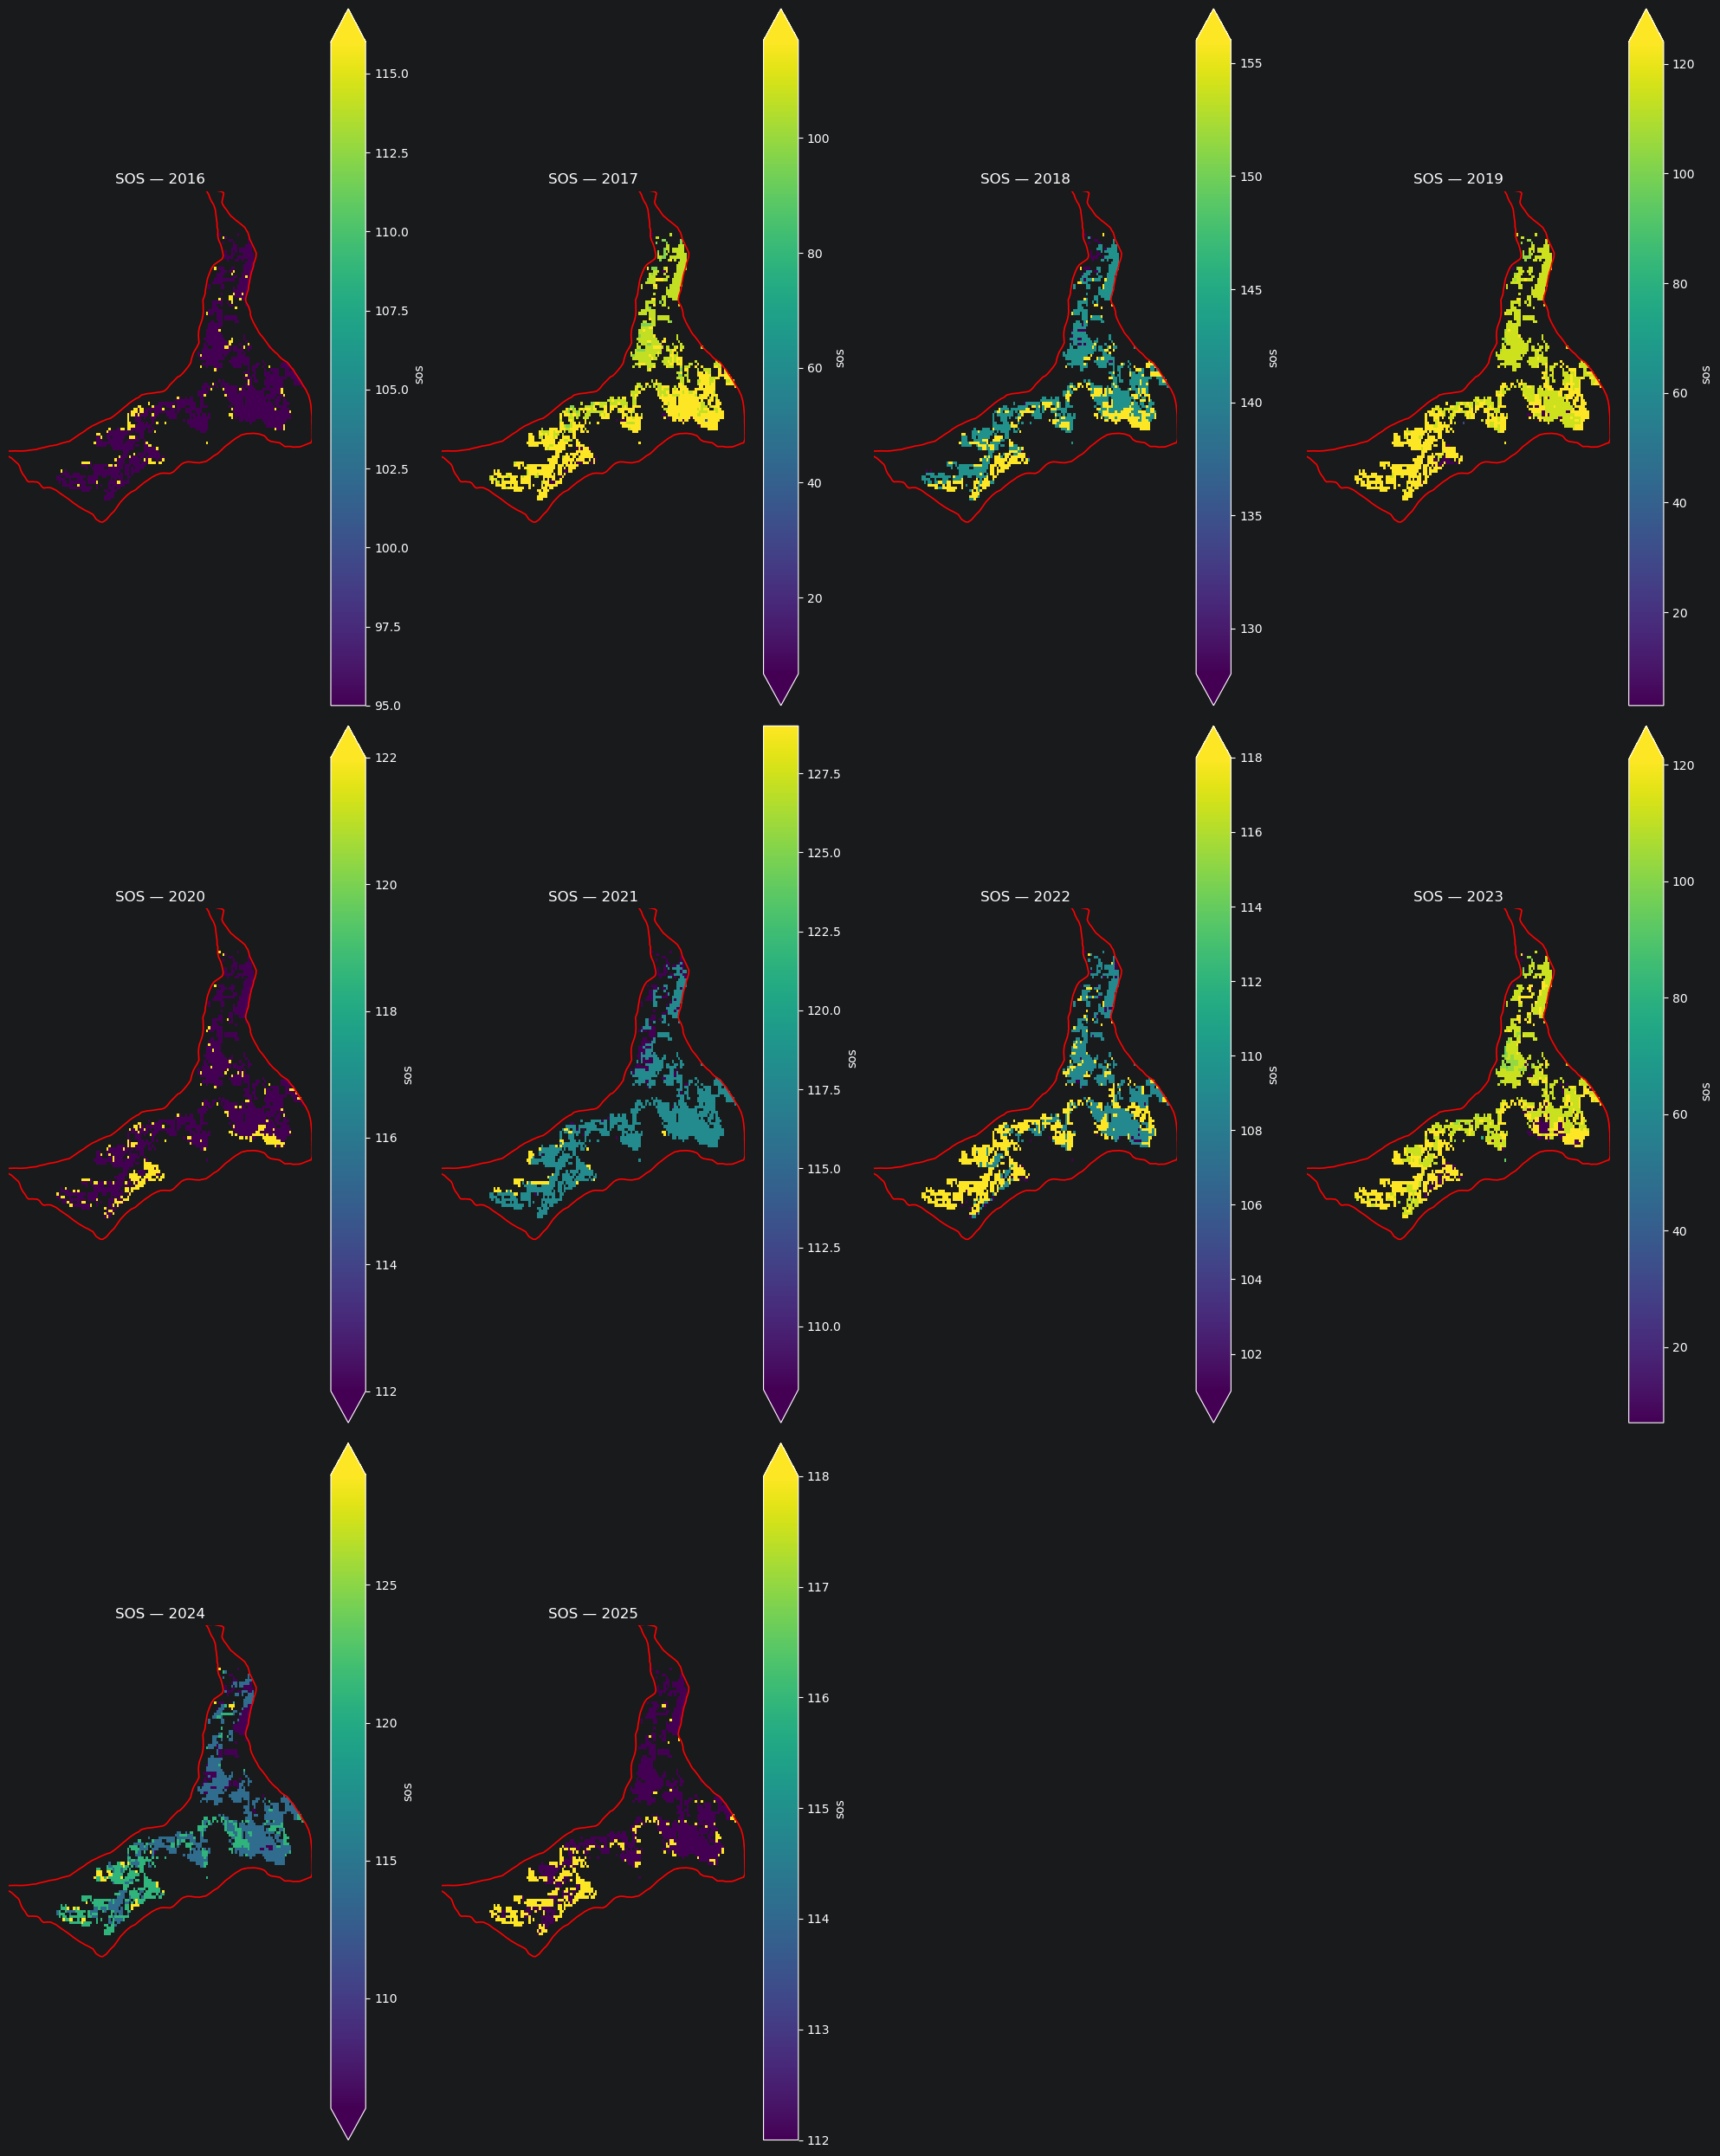

In [49]:
# region plot_sos


fig, axes = plt.subplots(
    3, 4,
    figsize=(20, 25),
    squeeze=False
)

axes = axes.flatten()

for ax, year in zip(axes, years):

    sos = results[year]["lsp"]["sos"]

    sos.plot(
        ax=ax,
        cmap="viridis",
        robust=True
    )

    gdf.boundary.plot(
        ax=ax,
        color="red",
        linewidth=1.2
    )

    ax.set_title(f"SOS — {year}")
    ax.set_axis_off()

for ax in axes[len(years):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

# endregion

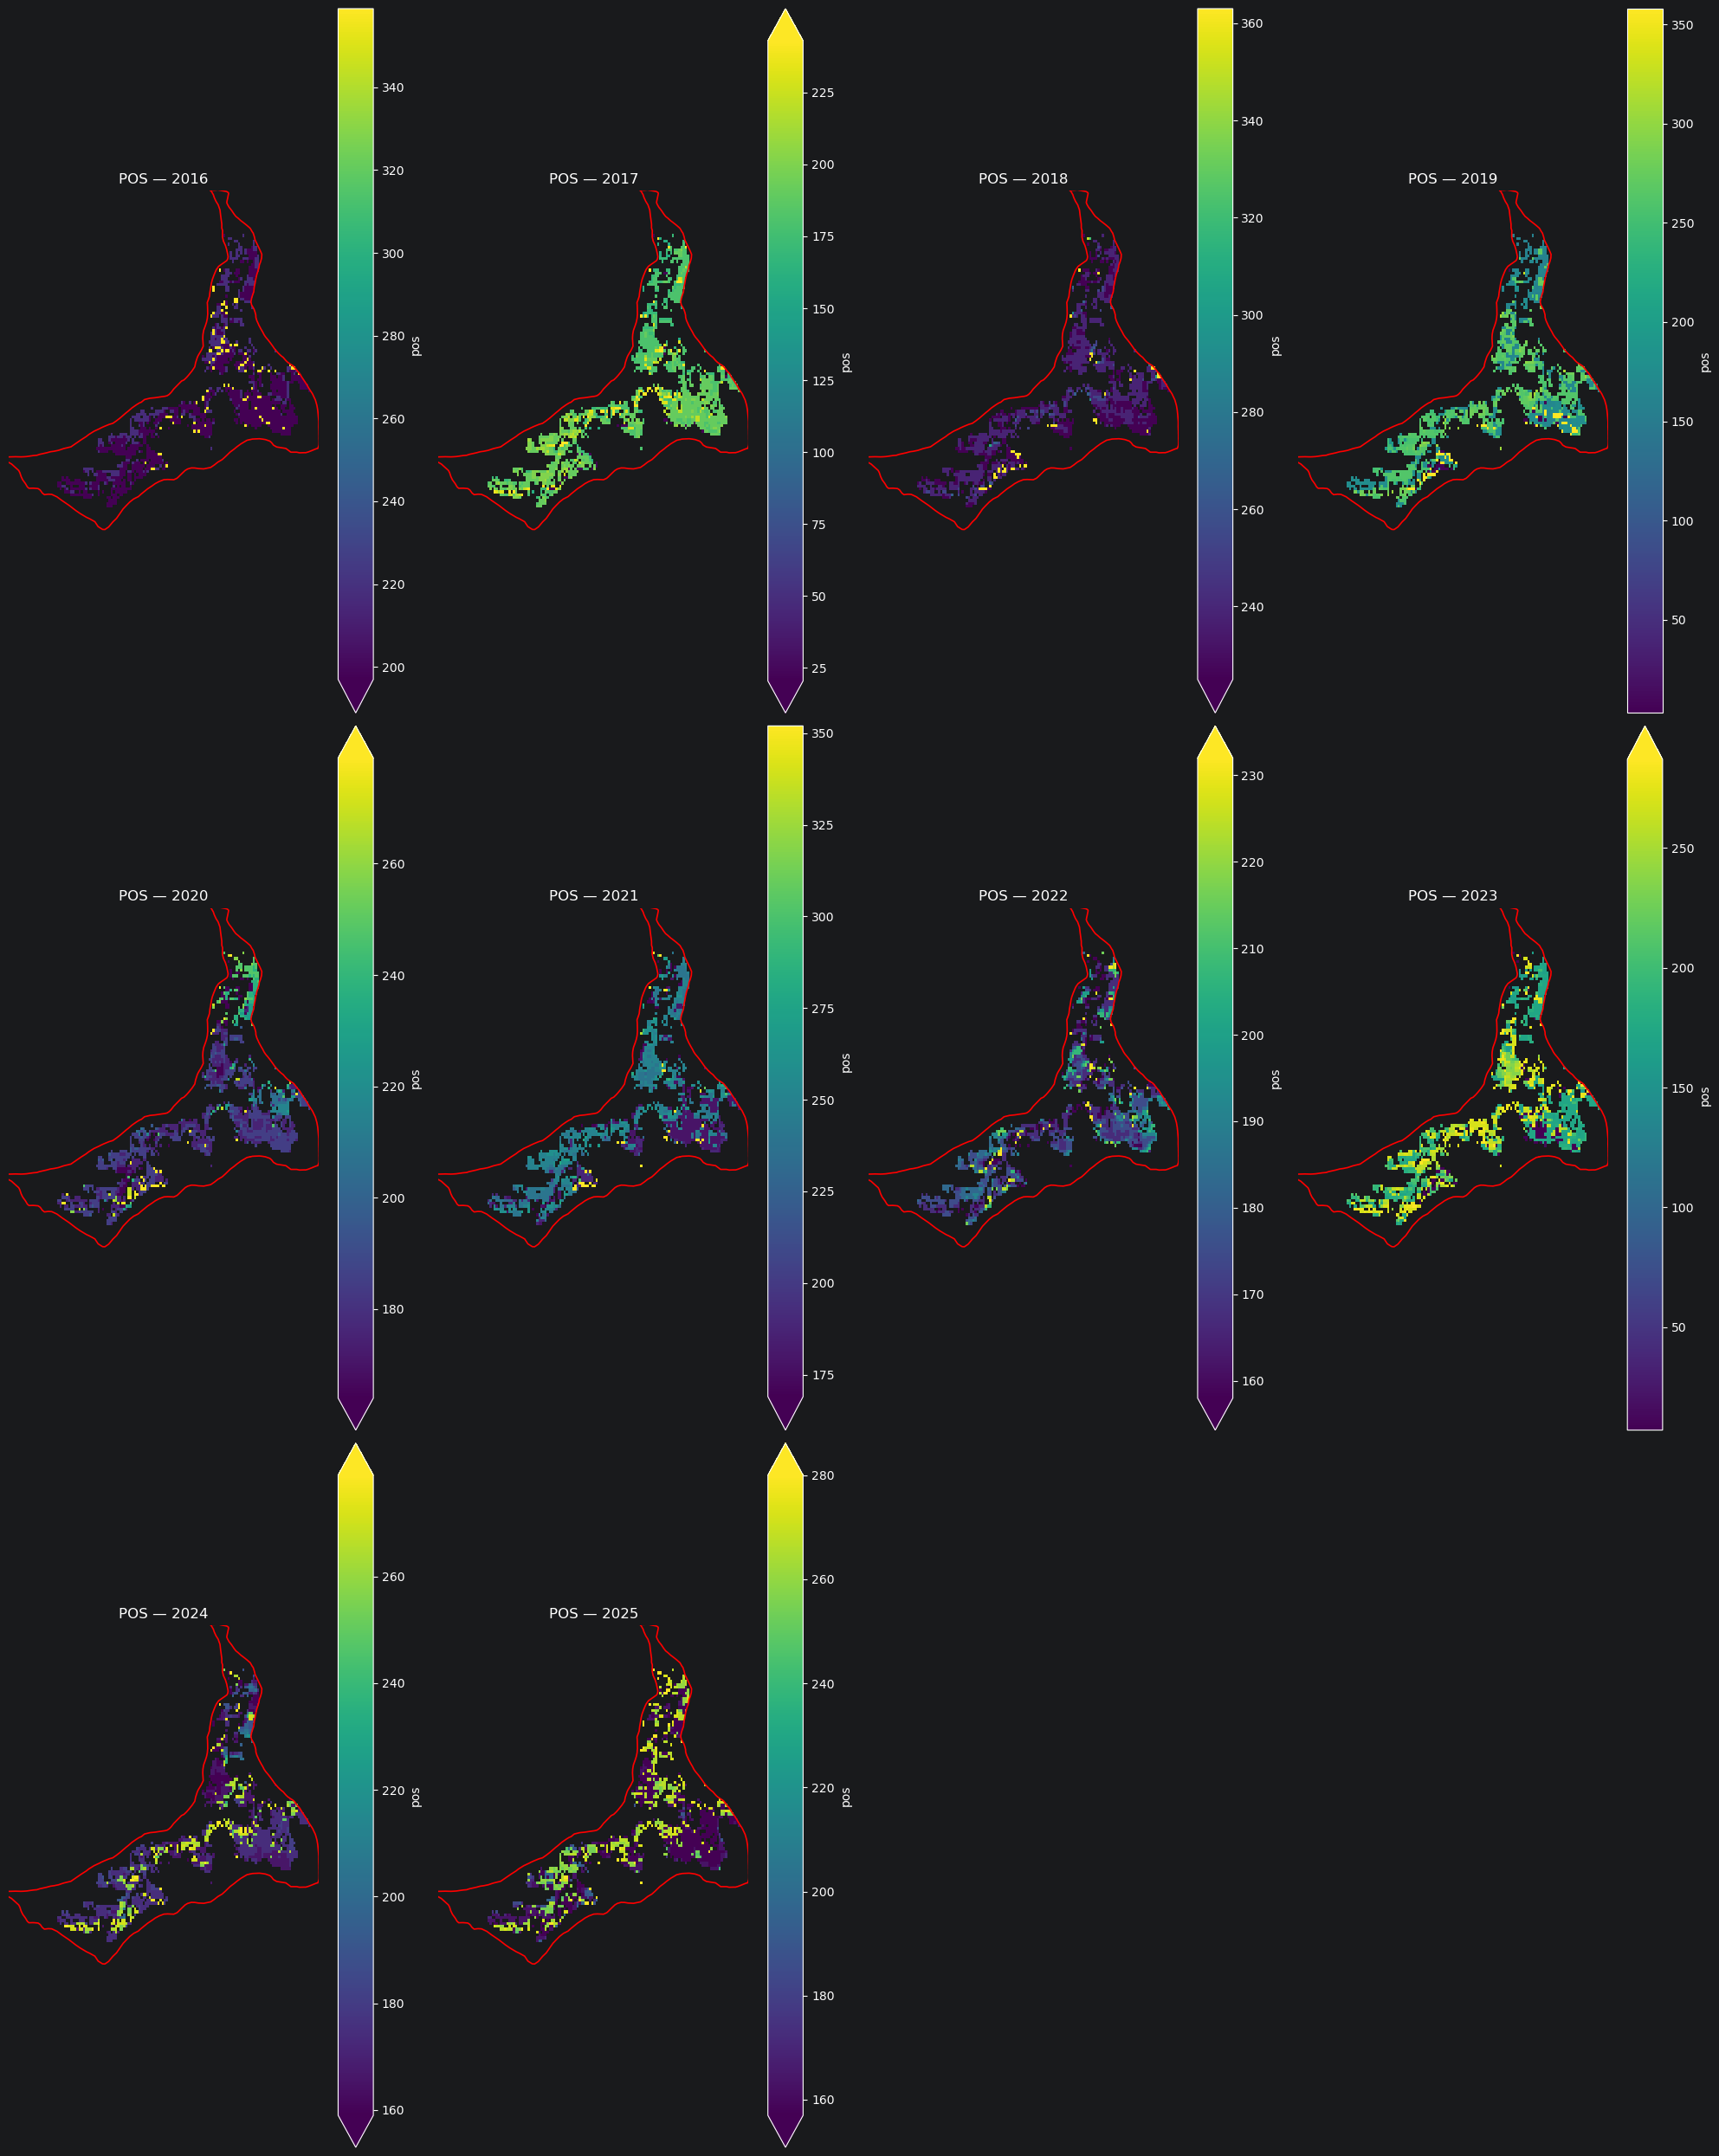

In [50]:
# region plot_pos


fig, axes = plt.subplots(
    3, 4,
    figsize=(20, 25),
    squeeze=False
)

axes = axes.flatten()

for ax, year in zip(axes, years):

    pos = results[year]["lsp"]["pos"]

    pos.plot(
        ax=ax,
        cmap="viridis",
        robust=True
    )

    gdf.boundary.plot(
        ax=ax,
        color="red",
        linewidth=1.2
    )

    ax.set_title(f"POS — {year}")
    ax.set_axis_off()

for ax in axes[len(years):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

# endregion

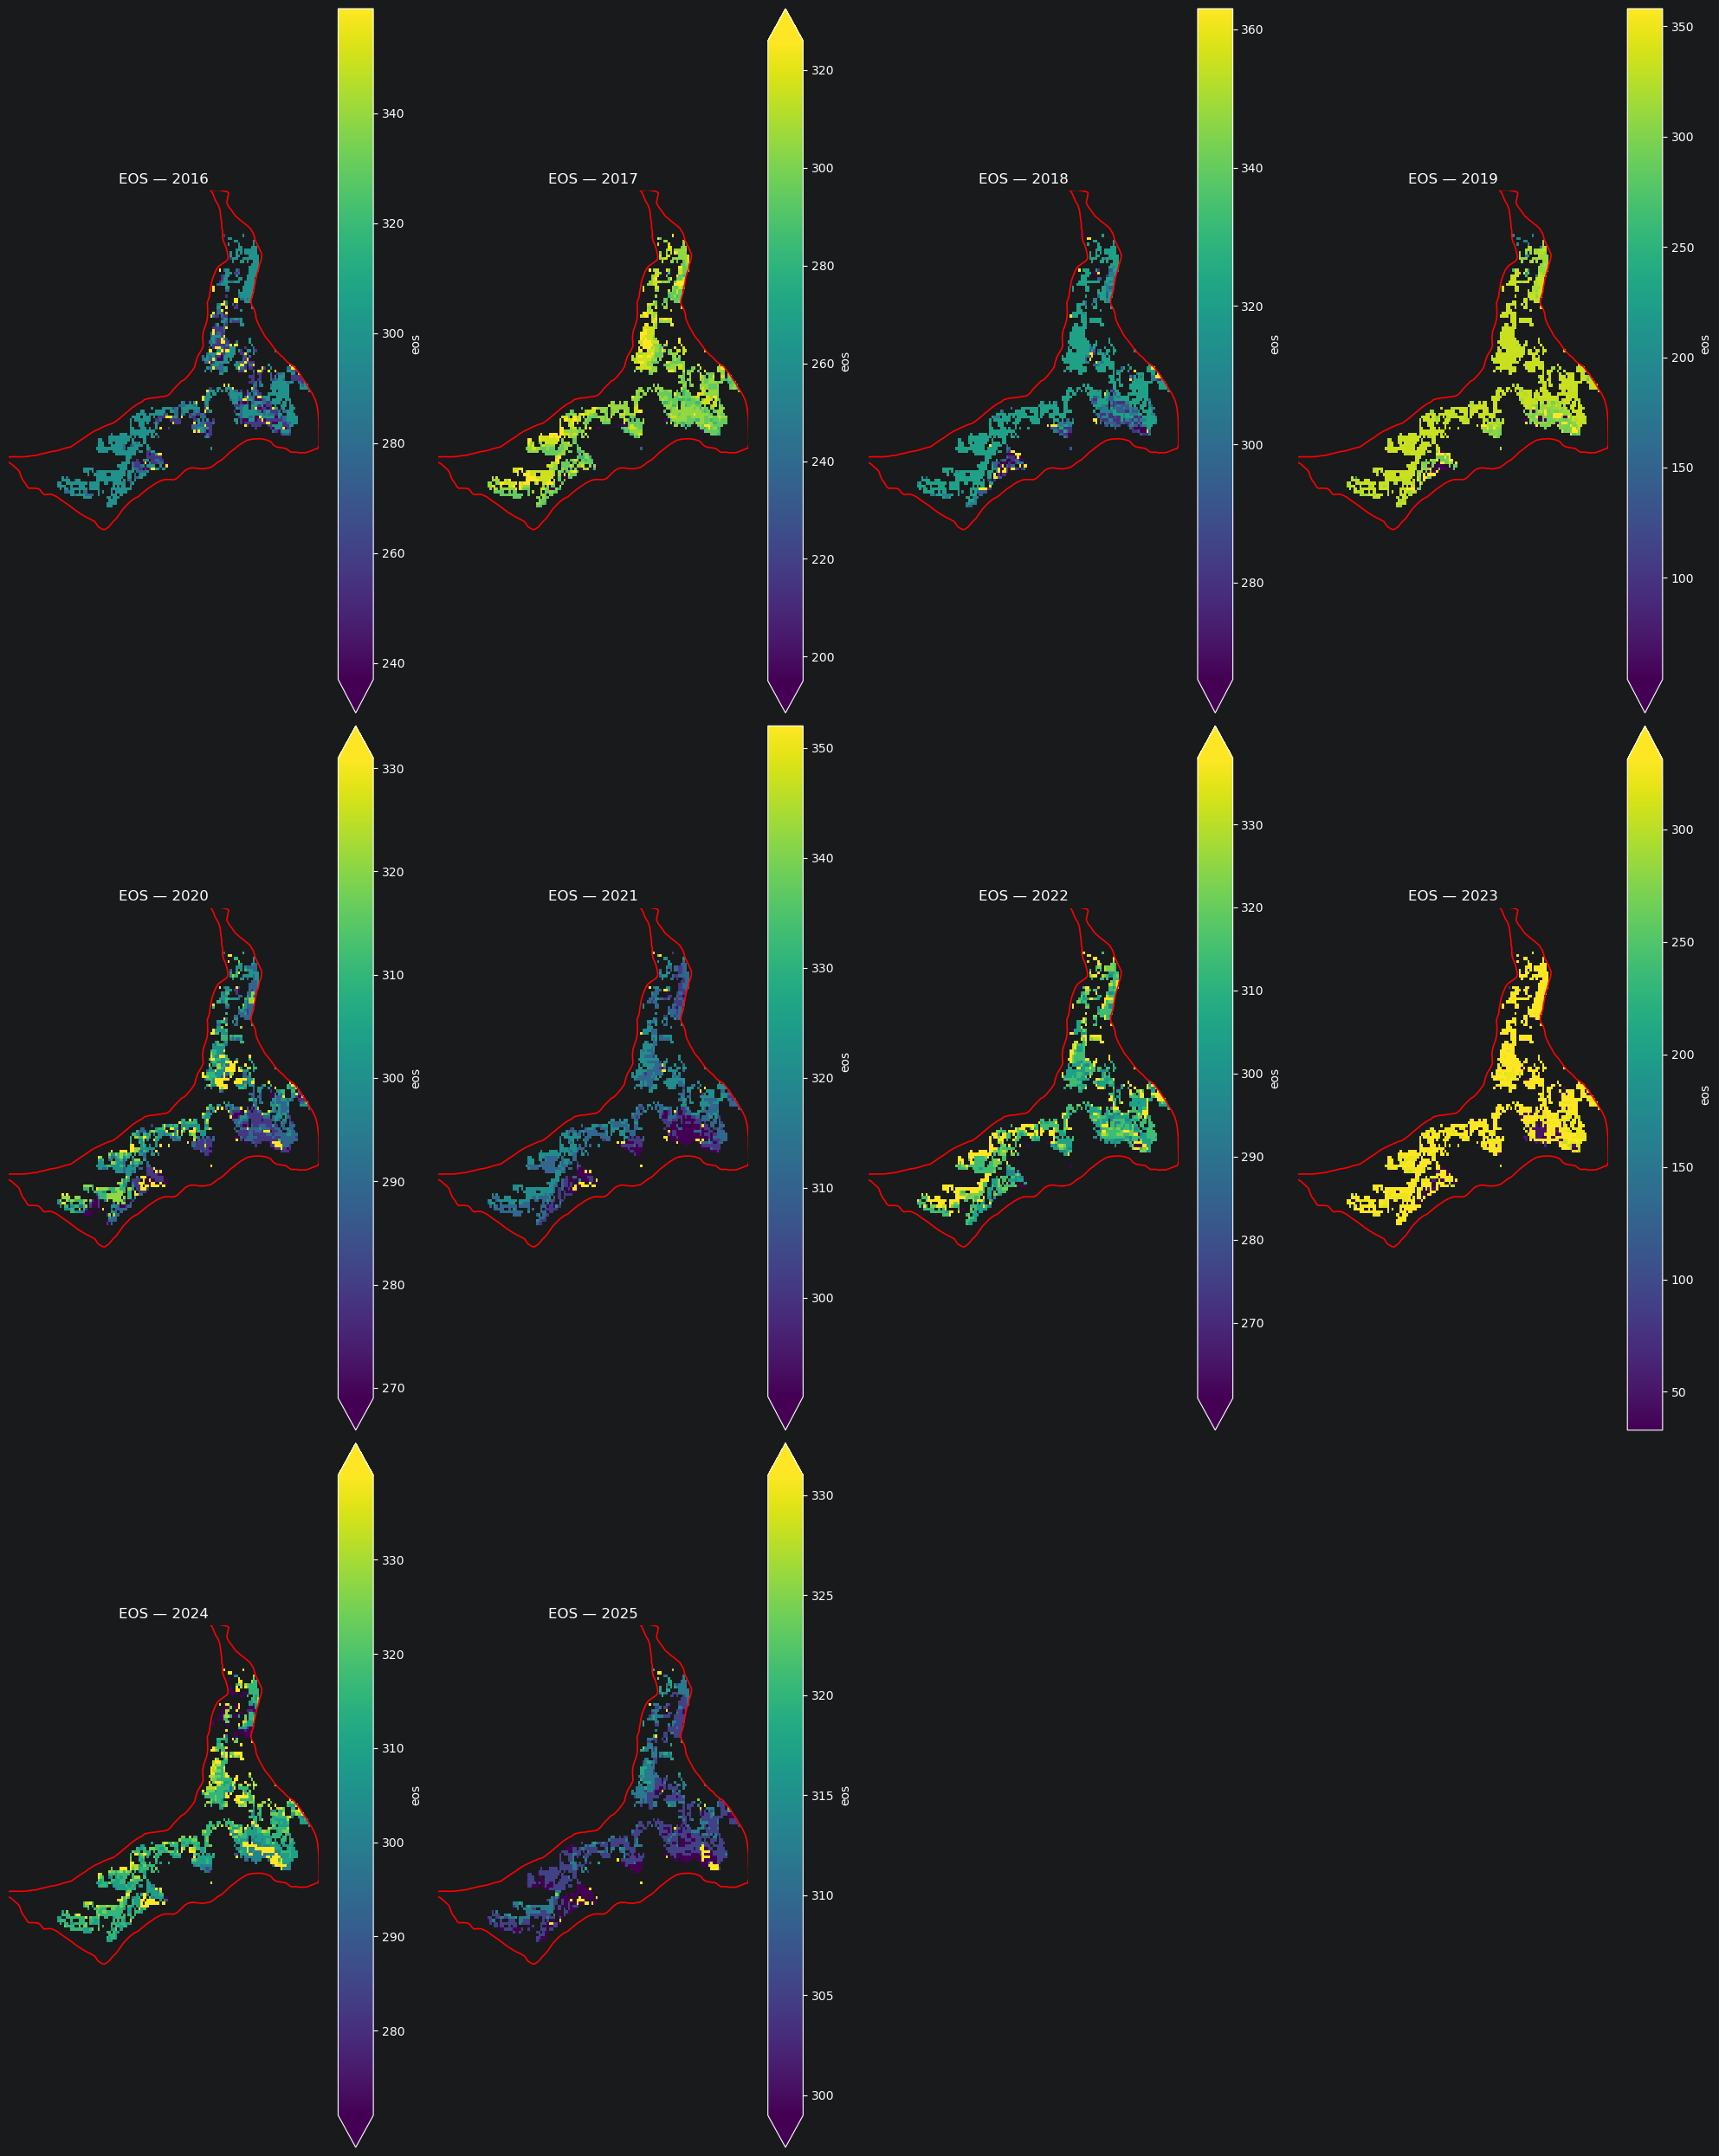

In [51]:
# region plot_eos


fig, axes = plt.subplots(
    3, 4,
    figsize=(20, 25),
    squeeze=False
)

axes = axes.flatten()

for ax, year in zip(axes, years):

    eos = results[year]["lsp"]["eos"]

    eos.plot(
        ax=ax,
        cmap="viridis",
        robust=True
    )

    gdf.boundary.plot(
        ax=ax,
        color="red",
        linewidth=1.2
    )

    ax.set_title(f"EOS — {year}")
    ax.set_axis_off()

for ax in axes[len(years):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

# endregion

# essai avec widget

In [53]:
#region widget
import ipywidgets as widgets
from IPython.display import display, clear_output



years = list(range(2016, 2026))

# Index de l'année 2016 = 0
year_index = 0


# --------------------------------------------------------
# Fonction d'affichage
# --------------------------------------------------------

def plot_phenology_year(metric, year):

    data = results[year]["lsp"][metric]

    median = float(
        data.median(skipna=True)
    )

    deviation = np.abs(
        data - median
    )


    # 90e percentile des écarts
    delta = float(
        deviation.quantile(0.9)
    )


    # Échelle symétrique autour de la médiane
    vmin = median - delta
    vmax = median + delta



    # ----------------------------------------------------
    # Figure
    # ----------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(12, 10)
    )

    data.plot(
        ax=ax,
        cmap="RdBu_r",
        vmin=vmin,
        vmax=vmax,
        add_colorbar=True
    )

    # Contour de la zone d'étude
    gdf.boundary.plot(
        ax=ax,
        color="black",
        linewidth=1
    )

    ax.set_title(
        f"{metric.upper()} — {year}\n"
        f"Médiane = {median:.1f} jours | "
        f"90e percentile = ±{delta:.1f} jours"
    )

    ax.set_axis_off()

    plt.tight_layout()
    plt.show()


# --------------------------------------------------------
# Widgets métriques
# --------------------------------------------------------

metric_selector = widgets.ToggleButtons(
    options=["sos", "pos", "eos"],
    value="sos",
    description="Métrique :"
)


previous_button = widgets.Button(
    description="Année précédente"
)

next_button = widgets.Button(
    description="Année suivante"
)


output = widgets.Output()


# --------------------------------------------------------
# Mise à jour de la carte
# --------------------------------------------------------

def update_plot():

    with output:
        clear_output(wait=True)

        plot_phenology_year(
            metric_selector.value,
            years[year_index]
        )


def previous_year(button):

    global year_index

    if year_index > 0:
        year_index -= 1

    update_plot()



def next_year(button):

    global year_index

    if year_index < len(years) - 1:
        year_index += 1

    update_plot()


# --------------------------------------------------------
# Changement de métrique
# --------------------------------------------------------

def change_metric(change):

    update_plot()


# --------------------------------------------------------
# Connexion des boutons
# --------------------------------------------------------

previous_button.on_click(previous_year)
next_button.on_click(next_year)

metric_selector.observe(
    change_metric,
    names="value"
)


# --------------------------------------------------------
# Affichage des contrôles
# --------------------------------------------------------

buttons = widgets.HBox([
    previous_button,
    next_button
])

display(
    widgets.VBox([
        metric_selector,
        buttons,
        output
    ])
)

# Affichage initial
update_plot()

# endregion